# Figure 4 — Reprogramming-associated regulatory networks

Run **Restart Kernel and Run All Cells**. Every panel is redrawn from checked numerical tables; no saved manuscript image is used as an input. The cells export new PNG/PDF/SVG files and assemble the complete figure.

This notebook follows the numerical manuscript snapshot dated 2026-10-13. Dataset display names were aligned with the manuscript on 2026-10-14: **RHY 1–4** denote the four rhynchophylline-versus-saline mouse brain datasets. Table previews use display names; the underlying CSV identifiers and numerical values remain unchanged. [Plotting source](../reproduction/figure4.py) · [Data provenance](../reproduction/manifest.json) · [Reproduction guide](README.md). The original model implementation and frozen selection remain unchanged. Training seeds measure optimization variability, not biological replication.

In [1]:
from pathlib import Path
import os
import sys

# Works from the repository root or notebooks/; an explicit root is optional.
configured = os.environ.get("SPIKE_CODE_ROOT")
REPO_ROOT = Path(configured).expanduser().resolve() if configured else next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "reproduction/manifest.json").is_file()
)
sys.path.insert(0, str(REPO_ROOT))
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
import matplotlib.pyplot as plt
from IPython.display import display
from reproduction.common import audit, read, save, finish, OUTPUT, display_table
from reproduction import figure4 as drawing

manifest = audit()
figures = {}


Input audit: PASS (33 numerical tables)
Figure protocol: Released manuscript graph predictions for all seven datasets; matched split-42 State, seeds 41/42/43. Original frozen model selection remains unchanged.


## A. Observed source cell types

PSAPP source-spot annotations on the recorded image coordinates. These are spatial spots, not single-cell-resolved measurements.

Numerical input: [`marker_strata_all_spots.csv`](../reproduction/tables/marker_strata_all_spots.csv).

Source table: marker_strata_all_spots.csv (6244, 7)


,barcode,x,y,plaque_score,stratum,drug,cell_type
0,AAACAAGTATCTCCCA-1-c,2571,2307,0.530124,proximal,control,Neuron
1,AAACACCAATAACTGC-1-c,748,2651,-0.345293,distal,control,Pericyte
2,AAACAGCTTTCAGAAG-1-c,528,2040,-0.096948,distal,control,Astrocyte
3,AAACAGGGTCTATATT-1-c,616,2193,-0.074885,intermediate,control,Astrocyte
4,AAACAGTGTTCCTGGG-1-c,1275,3186,-0.390887,distal,control,Astrocyte


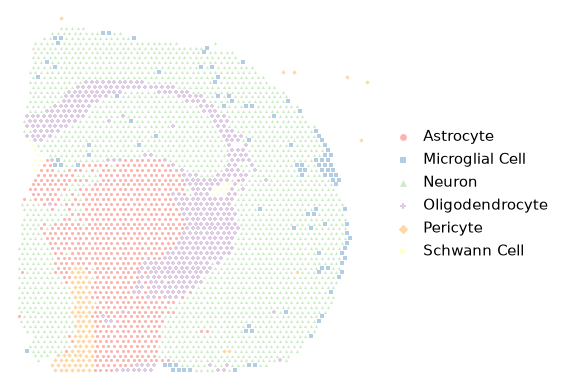

In [2]:
data_a = read('marker_strata_all_spots.csv')
print("Source table:", 'marker_strata_all_spots.csv', data_a.shape)
display(display_table(data_a.head(5)))
figures['a'] = drawing.panel_a()
save(figures['a'], 4, 'a')
display(figures['a'])
plt.close(figures['a'])

## B. Marker-score groups and response recovery

Low, middle and high source marker-score strata. Bars show response correlation and down-gene recovery; errors are training-seed SD. Marker strata are not measured plaque distances.

Numerical input: [`regional_response.csv`](../reproduction/tables/regional_response.csv).

Source table: regional_response.csv (2, 7)


,stratum,n_cells,spearman_pred_vs_obs,n_specific_down_genes,frac_specific_down_reproduced,spearman_pred_vs_obs_sd,frac_specific_down_reproduced_sd
0,distal,168.0,0.611845,39.0,0.863248,0.037632,0.064528
1,proximal,285.0,0.600413,216.0,0.904321,0.014402,0.005346


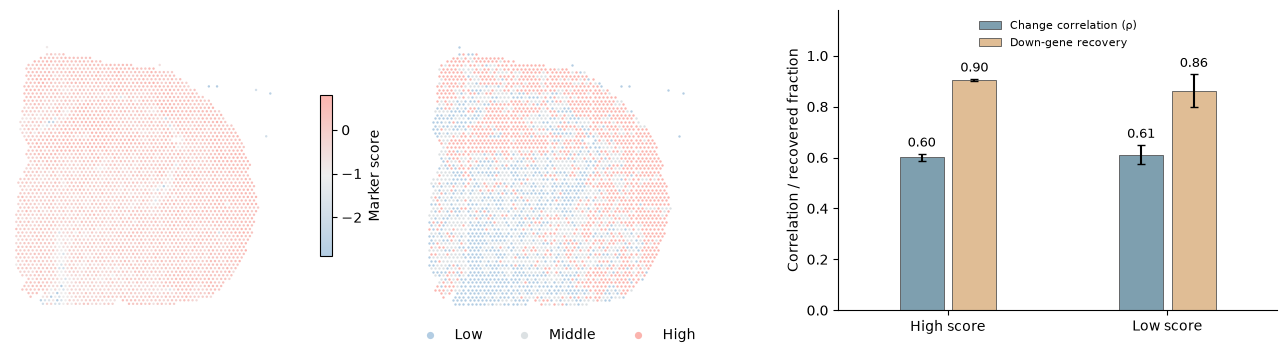

In [3]:
data_b = read('regional_response.csv')
print("Source table:", 'regional_response.csv', data_b.shape)
display(display_table(data_b.head(5)))
figures['b'] = drawing.panel_b()
save(figures['b'], 4, 'b')
display(figures['b'])
plt.close(figures['b'])

## C. Functional-module enrichment

Spike-inferred target genes. Bar lengths are −log10 of unadjusted enrichment P-values; end labels are overlap count/module size. These are exploratory enrichments.

Numerical input: [`module_enrichment.csv`](../reproduction/tables/module_enrichment.csv).

Source table: module_enrichment.csv (35, 9)


,Method,Module,Annotation,Overlap_Count,P_value,Cluster_Size,Method_Size,Log_P,Mod_Num
0,CellOT,M1,GOBP_SYNAPTIC_SIGNALING (Prkce+),13,0.570664,32,53,0.243619,1
1,scGPT,M1,GOBP_SYNAPTIC_SIGNALING (Prkce+),11,0.154327,32,34,0.811558,1
2,scGen,M1,GOBP_SYNAPTIC_SIGNALING (Prkce+),8,0.972059,32,49,0.012307,1
3,spike,M1,GOBP_SYNAPTIC_SIGNALING (Prkce+),17,0.029454,32,49,1.530854,1
4,state,M1,GOBP_SYNAPTIC_SIGNALING (Prkce+),2,0.989016,32,22,0.004797,1


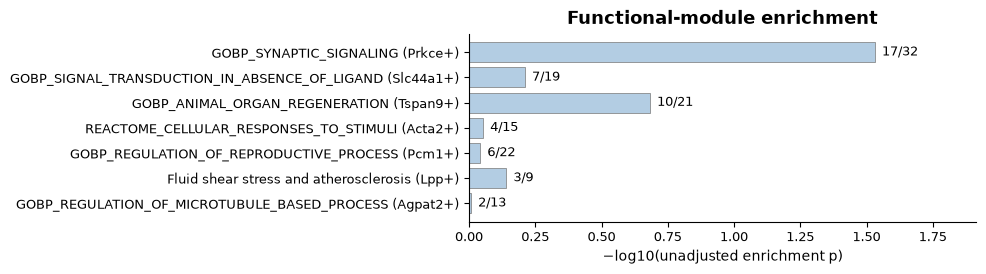

In [4]:
data_c = read('module_enrichment.csv')
print("Source table:", 'module_enrichment.csv', data_c.shape)
display(display_table(data_c.head(5)))
figures['c'] = drawing.panel_c()
save(figures['c'], 4, 'c')
display(figures['c'])
plt.close(figures['c'])

## D. GO/pathway enrichment

The ten recorded terms ranked by unadjusted enrichment P-value. Bar lengths are −log10(P).

Numerical input: [`go_enrichment.csv`](../reproduction/tables/go_enrichment.csv).

Source table: go_enrichment.csv (10, 6)


,Term,Method,P-value,Overlap_Count,Pathway_Size,Query_Size
0,GOBP_REGULATION_OF_FIBROBLAST_MIGRATION,spike,5.658551e-08,5,46,49
1,GOBP_REGULATION_OF_LOCOMOTION,spike,1.381107e-07,14,1159,49
2,GOBP_POSITIVE_REGULATION_OF_FIBROBLAST_MIGRATION,spike,1.536066e-07,4,22,49
3,GOBP_ACTIN_FILAMENT_BASED_PROCESS,spike,2.260532e-07,12,842,49
4,GOBP_FIBROBLAST_MIGRATION,spike,2.820523e-07,5,63,49


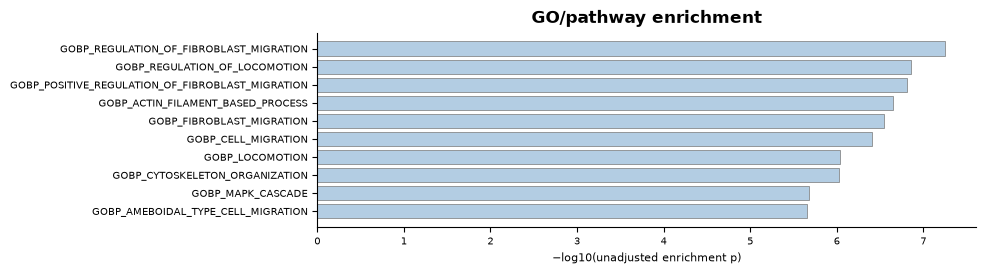

In [5]:
data_d = read('go_enrichment.csv')
print("Source table:", 'go_enrichment.csv', data_d.shape)
display(display_table(data_d.head(5)))
figures['d'] = drawing.panel_d()
save(figures['d'], 4, 'd')
display(figures['d'])
plt.close(figures['d'])

## E. Receptor–TF support networks

Five methods, one network each. Select up to 12 receptors and 12 TFs by maximum mean support, then the top 40 links with alphabetical tie-breaking. Mean support is min–max normalized over each method’s complete scored set before display; all panels use a 0–1 color and size scale. Complete aggregate tables for all five methods are included.

Numerical input: [`rt_spike.csv`](../reproduction/tables/rt_spike.csv).

Source table: rt_spike.csv (535, 3)


,receptor,tf,mean
0,Acvr2b,Cops5,0.200497
1,Acvr2b,Elk4,0.070192
2,Acvr2b,Esr1,0.043710
3,Acvr2b,Fosl1,0.034320
4,Acvr2b,Foxo1,0.051614


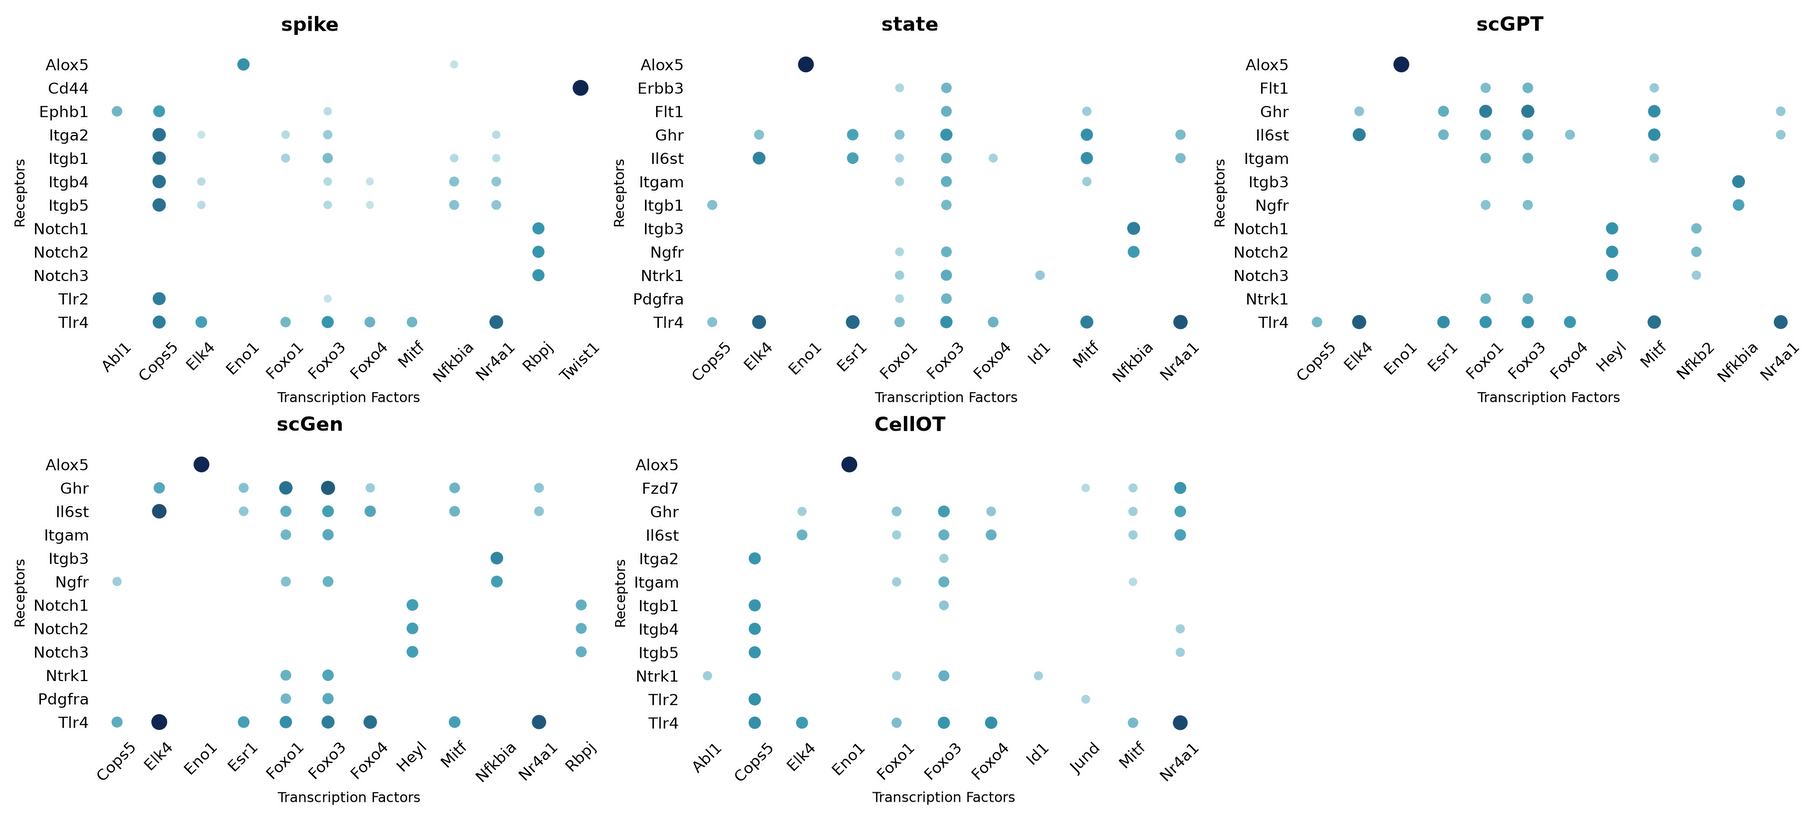

In [6]:
data_e = read('rt_spike.csv')
print("Source table:", 'rt_spike.csv', data_e.shape)
display(display_table(data_e.head(5)))
figures['e'] = drawing.panel_e()
save(figures['e'], 4, 'e')
display(figures['e'])
plt.close(figures['e'])

## F. Receptor–TF–target cascades

Spike above, State below. The shared display rule retains up to 6 TFs, 8 receptors and 20 targets. Ribbon widths derive from released link weights. These are inferred associations, not established causal transfer.

Numerical input: [`spike_tf_links.csv`](../reproduction/tables/spike_tf_links.csv).

Source table: spike_tf_links.csv (188, 3)


,receptor,tf,value
0,Acvr2b,Cops5,0.314385
1,Adora1,Elk4,0.340794
2,Adora1,Foxo1,0.281031
3,Adora1,Foxo4,0.320373
4,Adora1,Mitf,0.387154


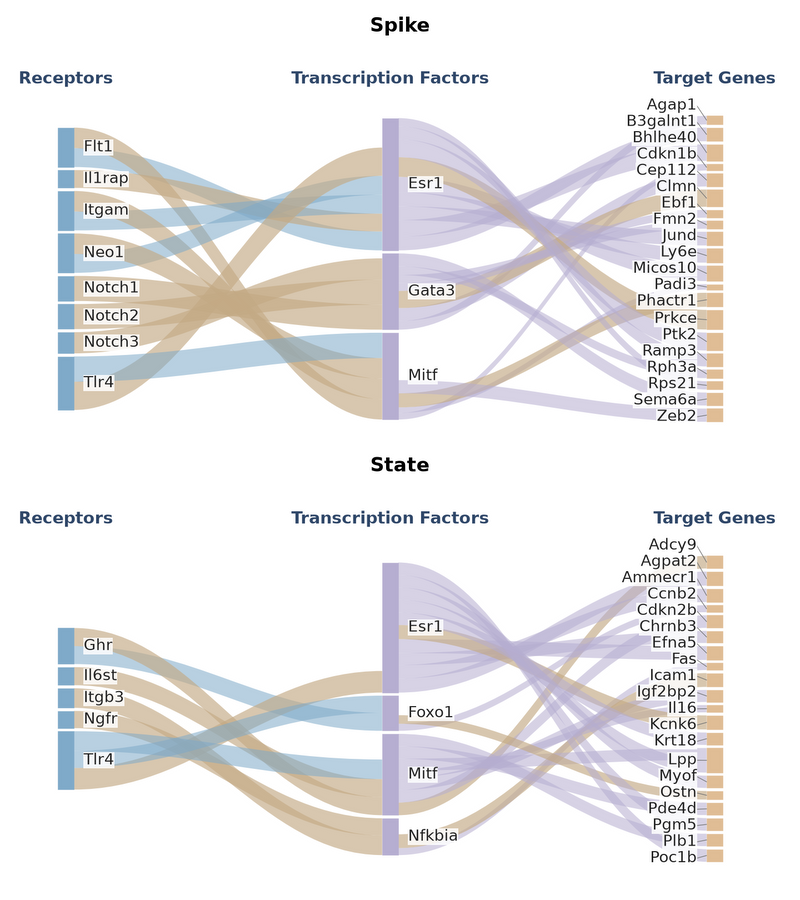

In [7]:
data_f = read('spike_tf_links.csv')
print("Source table:", 'spike_tf_links.csv', data_f.shape)
display(display_table(data_f.head(5)))
figures['f'] = drawing.panel_f()
save(figures['f'], 4, 'f')
display(figures['f'])
plt.close(figures['f'])

## G. Ttr distributions

RHY 1 (a different dataset from A–F): control, observed treated and Spike. Positive-value reflected KDE, 1.5 × Scott bandwidth, per-curve peak normalization; no paired-cell interpretation.

Numerical input: [`reprogramming_distributions.csv`](../reproduction/tables/reprogramming_distributions.csv).

Source table: reprogramming_distributions.csv (2744, 6)


,Expression,Source,Dataset,Gene,Seed,Cell
0,0.000000,Control,RHY 1,Sgk1,observed,AAAGTAGCATTGCTCA-1-c
1,2.001549,Control,RHY 1,Sgk1,observed,AAATAGGGTGCTATTG-1-c
2,2.496675,Control,RHY 1,Sgk1,observed,AAATGGCATGTCTTGT-1-c
3,2.129113,Control,RHY 1,Sgk1,observed,AAATGGTCAATGTGCC-1-c
4,1.434597,Control,RHY 1,Sgk1,observed,AAATTTGCGGGTGTGG-1-c


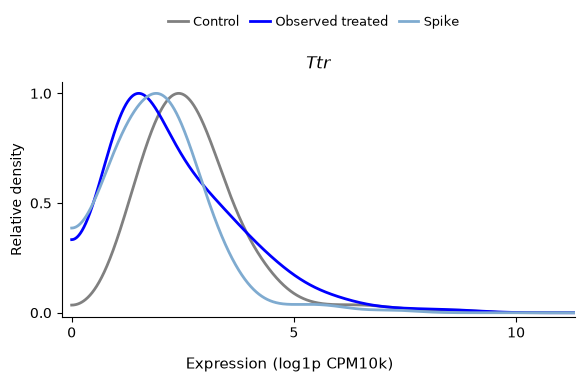

In [8]:
data_g = read('reprogramming_distributions.csv')
print("Source table:", 'reprogramming_distributions.csv', data_g.shape)
display(display_table(data_g.head(5)))
figures['g'] = drawing.panel_g()
save(figures['g'], 4, 'g')
display(figures['g'])
plt.close(figures['g'])

## Complete figure and output verification

The composite uses only the figures generated above, assembled in memory. It writes `complete.png`, `complete.pdf`, `complete.svg` and a validation record.

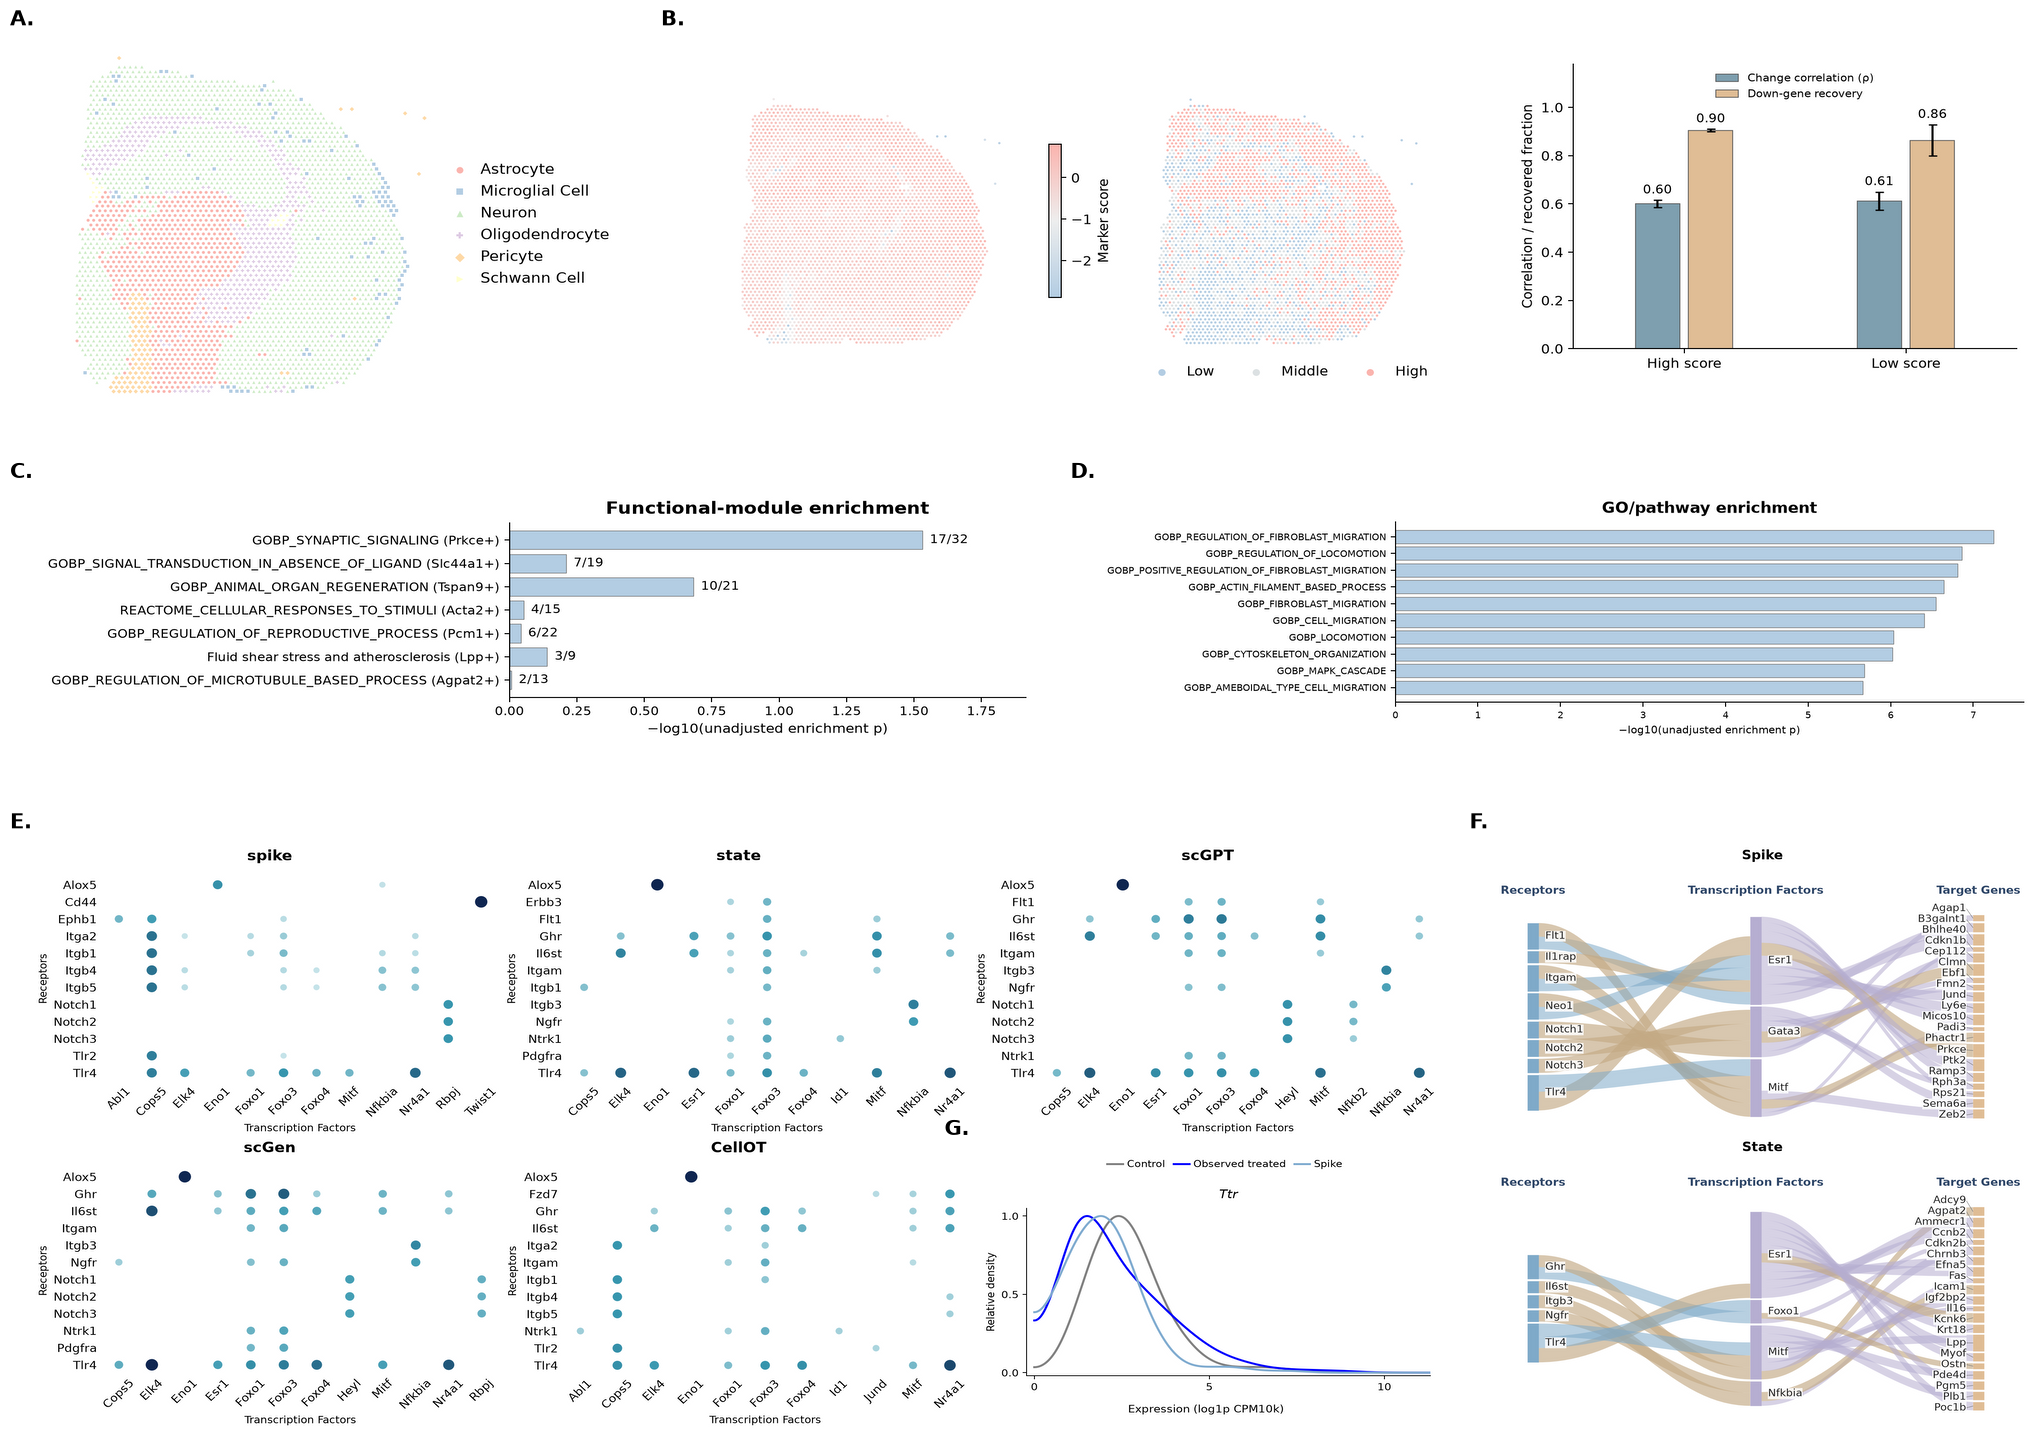

Figure 4: PASS — 7 panels redrawn from numerical tables
Outputs: /Users/jasmine/Documents/GitHub/spike/outputs/reproduction/figure4


In [9]:
complete = drawing.complete(figures)
save(complete, 4, "complete")
display(complete)
plt.close(complete)
report = finish(4, drawing.PANELS)